In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Load the COVID-19 dataset

df = pd.read_csv('/content/covid_19_clean_complete.csv')

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

df.head()

Dataset loaded successfully!
Number of rows and columns: (49068, 10)


,Province/State,Country/Region,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region
0,NaN,Afghanistan,33.93911,67.709953,2020-01-22,0,0,0,0,Eastern Mediterranean
1,NaN,Albania,41.15330,20.168300,2020-01-22,0,0,0,0,Europe
2,NaN,Algeria,28.03390,1.659600,2020-01-22,0,0,0,0,Africa
3,NaN,Andorra,42.50630,1.521800,2020-01-22,0,0,0,0,Europe
4,NaN,Angola,-11.20270,17.873900,2020-01-22,0,0,0,0,Africa


In [4]:
# Explore the dataset

print("Dataset Information:")
df.info()

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49068 entries, 0 to 49067
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Province/State  14664 non-null  object 
 1   Country/Region  49068 non-null  object 
 2   Lat             49068 non-null  float64
 3   Long            49068 non-null  float64
 4   Date            49068 non-null  object 
 5   Confirmed       49068 non-null  int64  
 6   Deaths          49068 non-null  int64  
 7   Recovered       49068 non-null  int64  
 8   Active          49068 non-null  int64  
 9   WHO Region      49068 non-null  object 
dtypes: float64(2), int64(4), object(4)
memory usage: 3.7+ MB

Column Names:
['Province/State', 'Country/Region', 'Lat', 'Long', 'Date', 'Confirmed', 'Deaths', 'Recovered', 'Active', 'WHO Region']

Missing Values:
Province/State    34404
Country/Region        0
Lat                   0
Long                  0
Date                

In [5]:
# Clean and prepare the dataset

# Convert Date column into datetime format
df['Date'] = pd.to_datetime(df['Date'])

# Check duplicate records
print("Duplicate rows:", df.duplicated().sum())

# Check date range
print("Starting Date:", df['Date'].min())
print("Ending Date:", df['Date'].max())

# Check number of countries
print("Total Countries:", df['Country/Region'].nunique())

# Check dataset shape
print("Dataset Shape:", df.shape)

Duplicate rows: 0
Starting Date: 2020-01-22 00:00:00
Ending Date: 2020-07-27 00:00:00
Total Countries: 187
Dataset Shape: (49068, 10)


In [6]:
# Aggregate data by country and date

daily_data = df.groupby(
    ['Country/Region', 'Date']
)[['Confirmed', 'Deaths', 'Recovered', 'Active']].sum().reset_index()

# Sort the data
daily_data = daily_data.sort_values(
    ['Country/Region', 'Date']
)

# Calculate daily new cases and deaths
daily_data['New Cases'] = daily_data.groupby(
    'Country/Region'
)['Confirmed'].diff().fillna(0)

daily_data['New Deaths'] = daily_data.groupby(
    'Country/Region'
)['Deaths'].diff().fillna(0)

# Calculate 7-day rolling averages
daily_data['7-Day Avg Cases'] = daily_data.groupby(
    'Country/Region'
)['New Cases'].transform(
    lambda x: x.rolling(7, min_periods=1).mean()
)

daily_data['7-Day Avg Deaths'] = daily_data.groupby(
    'Country/Region'
)['New Deaths'].transform(
    lambda x: x.rolling(7, min_periods=1).mean()
)

# Calculate Case Fatality Rate
daily_data['Case Fatality Rate (%)'] = (
    daily_data['Deaths'] / daily_data['Confirmed'].replace(0, np.nan)
) * 100

print("Analysis metrics created successfully!")

daily_data.head(10)

Analysis metrics created successfully!


,Country/Region,Date,Confirmed,Deaths,Recovered,Active,New Cases,New Deaths,7-Day Avg Cases,7-Day Avg Deaths,Case Fatality Rate (%)
0,Afghanistan,2020-01-22,0,0,0,0,0.0,0.0,0.0,0.0,NaN
1,Afghanistan,2020-01-23,0,0,0,0,0.0,0.0,0.0,0.0,NaN
2,Afghanistan,2020-01-24,0,0,0,0,0.0,0.0,0.0,0.0,NaN
3,Afghanistan,2020-01-25,0,0,0,0,0.0,0.0,0.0,0.0,NaN
4,Afghanistan,2020-01-26,0,0,0,0,0.0,0.0,0.0,0.0,NaN
5,Afghanistan,2020-01-27,0,0,0,0,0.0,0.0,0.0,0.0,NaN
6,Afghanistan,2020-01-28,0,0,0,0,0.0,0.0,0.0,0.0,NaN
7,Afghanistan,2020-01-29,0,0,0,0,0.0,0.0,0.0,0.0,NaN
8,Afghanistan,2020-01-30,0,0,0,0,0.0,0.0,0.0,0.0,NaN
9,Afghanistan,2020-01-31,0,0,0,0,0.0,0.0,0.0,0.0,NaN


In [7]:
# Calculate doubling time using 7-day growth

daily_data['Previous 7-Day Cases'] = daily_data.groupby(
    'Country/Region'
)['Confirmed'].shift(7)

daily_data['Doubling Time (Days)'] = np.where(
    (daily_data['Confirmed'] > daily_data['Previous 7-Day Cases']) &
    (daily_data['Previous 7-Day Cases'] > 0),
    7 * np.log(2) / np.log(
        daily_data['Confirmed'] / daily_data['Previous 7-Day Cases']
    ),
    np.nan
)

print("Doubling time calculated successfully!")

daily_data[['Country/Region', 'Date', 'Confirmed',
            'Previous 7-Day Cases', 'Doubling Time (Days)']].tail(10)

Doubling time calculated successfully!


,Country/Region,Date,Confirmed,Previous 7-Day Cases,Doubling Time (Days)
35146,Zimbabwe,2020-07-18,1478,982.0,11.867397
35147,Zimbabwe,2020-07-19,1611,985.0,9.862477
35148,Zimbabwe,2020-07-20,1713,1034.0,9.611569
35149,Zimbabwe,2020-07-21,1820,1064.0,9.038786
35150,Zimbabwe,2020-07-22,2034,1089.0,7.766424
35151,Zimbabwe,2020-07-23,2124,1362.0,10.919465
35152,Zimbabwe,2020-07-24,2296,1420.0,10.097634
35153,Zimbabwe,2020-07-25,2434,1478.0,9.726506
35154,Zimbabwe,2020-07-26,2512,1611.0,10.922482
35155,Zimbabwe,2020-07-27,2704,1713.0,10.629090


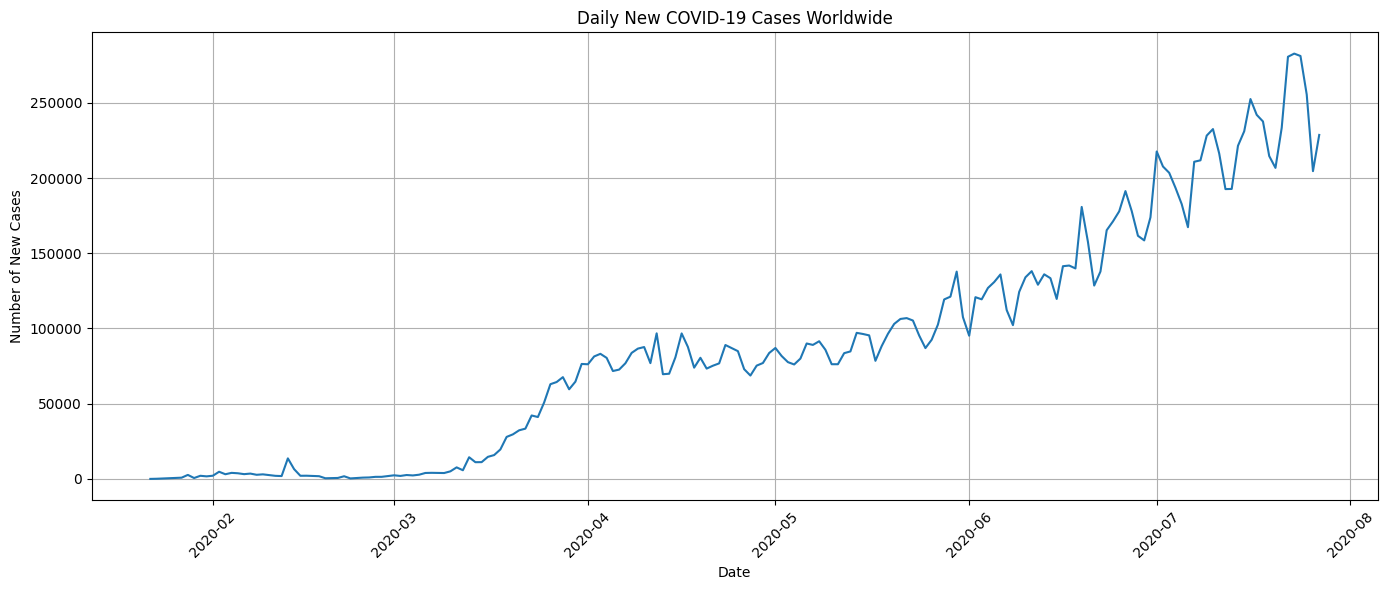

In [8]:
# Daily worldwide COVID-19 cases

world_daily = daily_data.groupby('Date')['New Cases'].sum().reset_index()

plt.figure(figsize=(14, 6))

plt.plot(world_daily['Date'], world_daily['New Cases'])

plt.title('Daily New COVID-19 Cases Worldwide')
plt.xlabel('Date')
plt.ylabel('Number of New Cases')

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

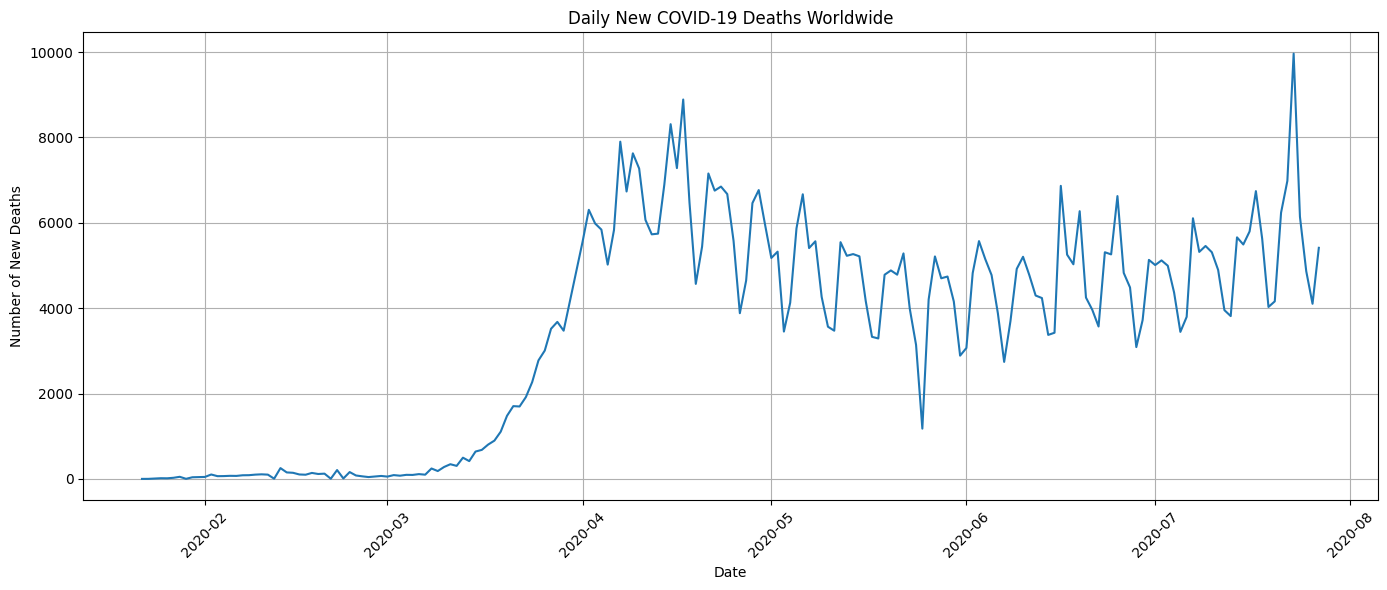

In [9]:
# Daily worldwide COVID-19 deaths

world_deaths = daily_data.groupby('Date')['New Deaths'].sum().reset_index()

plt.figure(figsize=(14, 6))

plt.plot(world_deaths['Date'], world_deaths['New Deaths'])

plt.title('Daily New COVID-19 Deaths Worldwide')
plt.xlabel('Date')
plt.ylabel('Number of New Deaths')

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

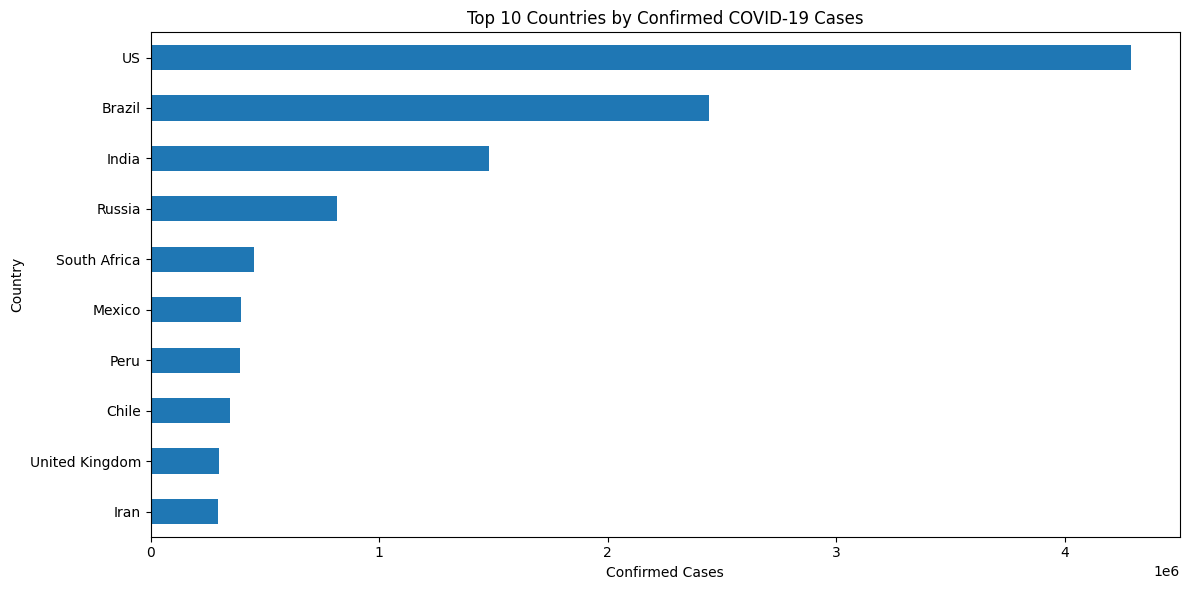

In [10]:
# Top 10 countries by confirmed COVID-19 cases

country_cases = df.groupby('Country/Region')['Confirmed'].max()

top_10 = country_cases.sort_values(ascending=False).head(10)

plt.figure(figsize=(12, 6))

top_10.sort_values().plot(kind='barh')

plt.title('Top 10 Countries by Confirmed COVID-19 Cases')
plt.xlabel('Confirmed Cases')
plt.ylabel('Country')

plt.tight_layout()
plt.show()

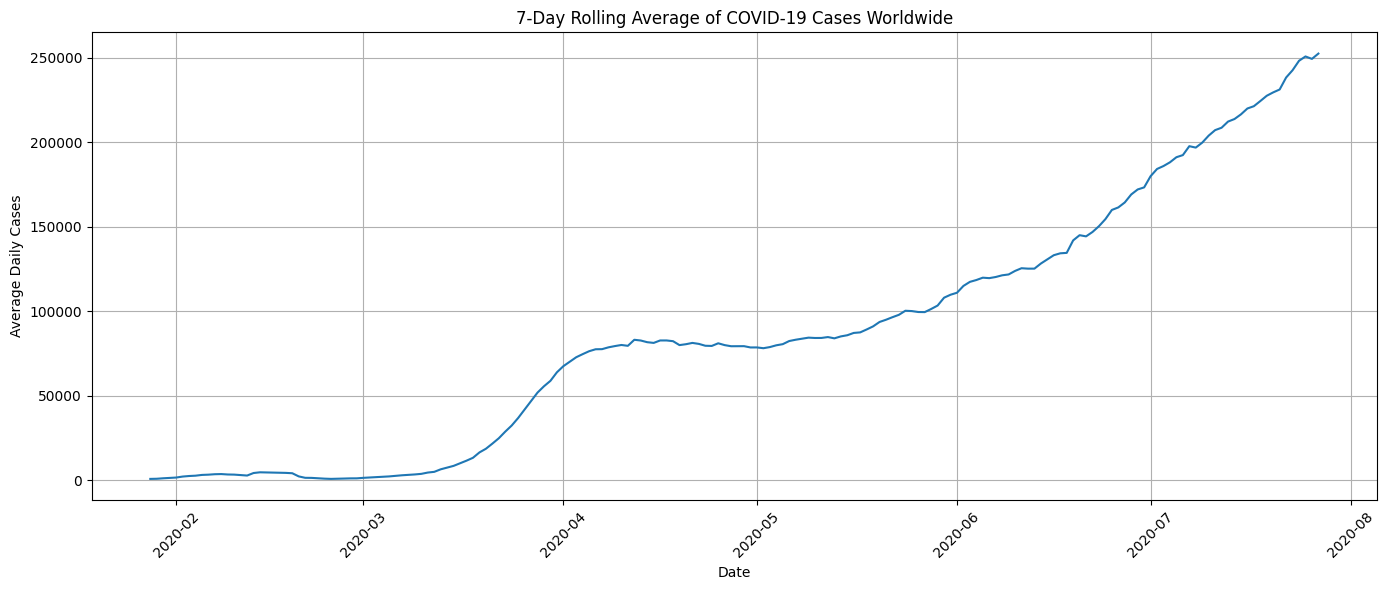

In [11]:
# Worldwide 7-day rolling average

rolling_cases = daily_data.groupby('Date')['New Cases'].sum().rolling(7).mean()

plt.figure(figsize=(14, 6))

plt.plot(rolling_cases.index, rolling_cases.values)

plt.title('7-Day Rolling Average of COVID-19 Cases Worldwide')
plt.xlabel('Date')
plt.ylabel('Average Daily Cases')

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

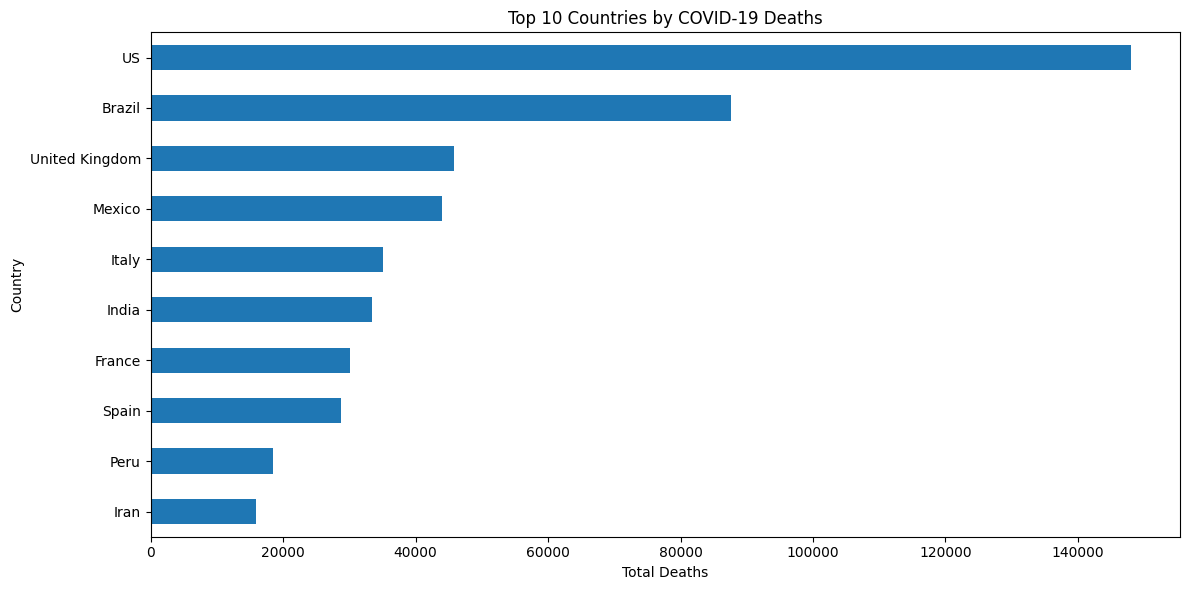

In [12]:
# Top 10 countries by COVID-19 deaths

country_deaths = df.groupby('Country/Region')['Deaths'].max()

top_deaths = country_deaths.sort_values(ascending=False).head(10)

plt.figure(figsize=(12, 6))

top_deaths.sort_values().plot(kind='barh')

plt.title('Top 10 Countries by COVID-19 Deaths')
plt.xlabel('Total Deaths')
plt.ylabel('Country')

plt.tight_layout()
plt.show()

In [14]:
country_summary = df.groupby('Country/Region').agg({
    'Confirmed': 'max',
    'Deaths': 'max',
    'Recovered': 'max',
    'Active': 'max'
})

top_countries = country_summary.sort_values(
    by='Confirmed', ascending=False
).head(10)

top_countries

,Confirmed,Deaths,Recovered,Active
Country/Region,,,,
US,4290259,148011,1325804,2816444
Brazil,2442375,87618,1846641,583080
India,1480073,33408,951166,495499
Russia,816680,13334,602249,245382
South Africa,452529,7067,274925,173590
Mexico,395489,44022,303810,53572
Peru,389717,18418,272547,108616
Chile,347923,9187,319954,82961
United Kingdom,300111,45759,533,254352


<Figure size 1200x600 with 0 Axes>

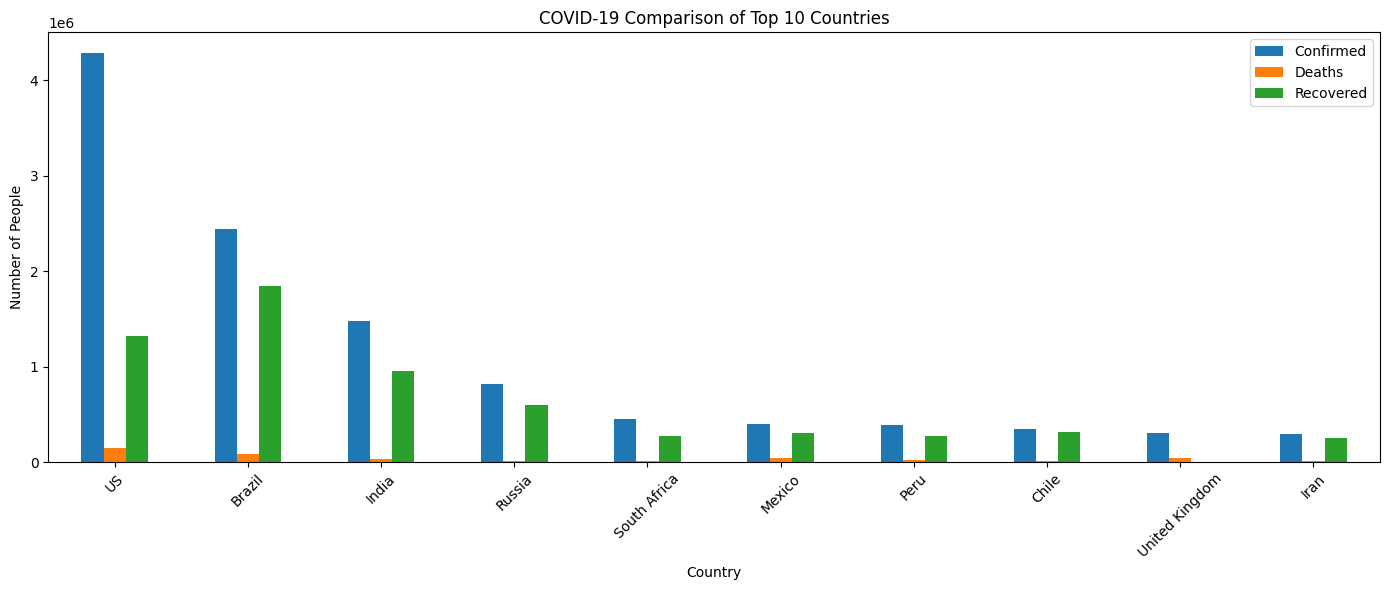

In [15]:
plt.figure(figsize=(12, 6))

top_countries[['Confirmed', 'Deaths', 'Recovered']].plot(
    kind='bar',
    figsize=(14, 6)
)

plt.title('COVID-19 Comparison of Top 10 Countries')
plt.xlabel('Country')
plt.ylabel('Number of People')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [16]:
print("COVID-19 DATA ANALYSIS SUMMARY")
print("--------------------------------")

print("Total Countries:", df['Country/Region'].nunique())
print("Total Confirmed Cases:", df.groupby('Country/Region')['Confirmed'].max().sum())
print("Total Deaths:", df.groupby('Country/Region')['Deaths'].max().sum())
print("Total Recovered:", df.groupby('Country/Region')['Recovered'].max().sum())
print("Total Active Cases:", df.groupby('Country/Region')['Active'].max().sum())
print("Data Period:", df['Date'].min().date(), "to", df['Date'].max().date())

COVID-19 DATA ANALYSIS SUMMARY
--------------------------------
Total Countries: 187
Total Confirmed Cases: 16384144
Total Deaths: 650633
Total Recovered: 9453827
Total Active Cases: 7165770
Data Period: 2020-01-22 to 2020-07-27


In [17]:
insights = [
    "The United States recorded the highest number of confirmed COVID-19 cases.",
    "Brazil ranked second and India ranked third in confirmed cases.",
    "The United States recorded the highest number of deaths among the top 10 countries.",
    "Worldwide daily COVID-19 cases increased during the study period.",
    "The dataset covers 187 countries from January 22 to July 27, 2020."
]

print("KEY FINDINGS")
print("----------------")
for i, insight in enumerate(insights, 1):
    print(f"{i}. {insight}")

KEY FINDINGS
----------------
1. The United States recorded the highest number of confirmed COVID-19 cases.
2. Brazil ranked second and India ranked third in confirmed cases.
3. The United States recorded the highest number of deaths among the top 10 countries.
4. Worldwide daily COVID-19 cases increased during the study period.
5. The dataset covers 187 countries from January 22 to July 27, 2020.


In [18]:
daily_data.to_csv('COVID_19_Cleaned_Data.csv', index=False)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!


In [20]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

world_trend = daily_data.groupby('Date')[
    ['New Cases', 'New Deaths']
].sum().reset_index()

fig = make_subplots(
    rows=2, cols=1,
    subplot_titles=(
        'Daily New COVID-19 Cases Worldwide',
        'Daily New COVID-19 Deaths Worldwide'
    )
)

fig.add_trace(
    go.Scatter(
        x=world_trend['Date'],
        y=world_trend['New Cases'],
        mode='lines',
        name='New Cases'
    ),
    row=1, col=1
)

fig.add_trace(
    go.Scatter(
        x=world_trend['Date'],
        y=world_trend['New Deaths'],
        mode='lines',
        name='New Deaths'
    ),
    row=2, col=1
)

fig.update_layout(
    title='COVID-19 Interactive Dashboard',
    height=750,
    template='plotly_white'
)

fig.show()

In [21]:
import plotly.express as px

country_chart = top_countries.reset_index()

fig = px.bar(
    country_chart,
    x='Country/Region',
    y='Confirmed',
    color='Country/Region',
    title='Top 10 Countries by Confirmed COVID-19 Cases',
    hover_data=['Deaths', 'Recovered', 'Active']
)

fig.update_layout(
    xaxis_title='Country',
    yaxis_title='Confirmed Cases',
    showlegend=False
)

fig.show()